# Small project Predicting house price


MedInc	구역 소득 중앙값 (단위: 1만 달러)

HouseAge 	주택 연식 중앙값

AveRooms     가구당 평균 방 수

AveBedrms	가구당 평균 침실 수

Population	구역 인구

AveOccup	가구당 평균 거주 인원

Latitude	위도

Longitude	경도

MedHouseVal  주택 가격

feature들을 가지고 주택 가격을 예측하는 문제


# 1. 선형 회귀
# 2. feature engineering
# 3. Kernel

--> 각각 장단점 비교



In [1]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [ ]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
print(df.shape)   # (20640, 9)
print(df.head)

# 1) 2000개 무작위 샘플링
df_s = df.sample(n=2000, random_state=0)

print(df_s[:100])

(20640, 9)
<bound method NDFrame.head of        MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0      8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1      8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2      7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3      5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4      3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   
...       ...       ...       ...        ...         ...       ...       ...   
20635  1.5603      25.0  5.045455   1.133333       845.0  2.560606     39.48   
20636  2.5568      18.0  6.114035   1.315789       356.0  3.122807     39.49   
20637  1.7000      17.0  5.205543   1.120092      1007.0  2.325635     39.43   
20638  1.8672      18.0  5.329513   1.171920       741.0  2.123209     39.43   
20639  2.3886      16.0  5.254717   1.162264      1387.0  2.616981     39.37   

In [22]:
X = df_s.drop(columns="MedHouseVal").to_numpy()
y = df_s["MedHouseVal"].to_numpy()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)
print(X_tr.shape, X_te.shape)   # (1600, 8) (400, 8)

(1600, 8) (400, 8)


In [13]:
scaler = StandardScaler().fit(X_tr)
X_tr = scaler.transform(X_tr)
X_te = scaler.transform(X_te)

# 4) y도 표준화 (학습 안정화)
y_mean, y_std = y_tr.mean(), y_tr.std()
y_tr_s = (y_tr - y_mean) / y_std

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def linear_f(x,w,b):
    #Multivariate linear function
    #return vector of y predict
    #[y1,y2,y4] = #[x1w1 +b ,x2w2+b,x3w3+b..]

    return x @ w + b

def mse_loss(x,y,w,b):
    #loss per sample
    #return loss vector
    y_pred = linear_f(x,w,b)
    return 0.5 * (y - y_pred) ** 2

def grad_w_mse(x,y,w,b):

    return (linear_f(x,w,b)-y) * x

def grad_b_mse(x,y,w,b):

    return (linear_f(x,w,b)-y) * 1


def Gradient_decent(x,y,learning_rate,batch_size,epochs,seed = None,grad_reduce="mean"):
    """
    Gradient descent algorithm to optimize the weight and bias
    :param x: input data
    :param y: true labels
    :param learning_rate: learning rate for gradient descent
    :param batch_size: size of each batch for mini-batch gradient descent
    :param epochs: number of iterations for gradient descent
    :return: optimized weight and bias
    """

    #N  is number of data, D is dimention of x
    N,D = x.shape
    
    rng = np.random.default_rng(seed)
    w = rng.standard_normal(D)
    b = rng.standard_normal()

    history = {'w': [w], 'b': [b], 'loss': [np.mean(mse_loss(x,y,w,b))]}

    points = 0

    for epoch in range(epochs):
        #suffle data with idx
        idx = rng.permutation(N)
        #idx is array of suffle number between 0 ~ N 
        
        for start in range(0,N,batch_size):
            #from 0 ~ N step of batch_size
            
            batch = idx[start:start+batch_size]

            #dw => 0 vector sizeOF D
            #db = 0
            dw,db = np.zeros(D),0.0

            for j in batch :
                dw = dw + grad_w_mse(x[j],y[j],w,b)
                db = db + grad_b_mse(x[j],y[j],w,b)
            if grad_reduce == "mean":
                dw /= len(batch)
                db /= len(batch)

            w = w - learning_rate*dw
            b = b - learning_rate*db

            loss = np.mean(mse_loss(x,y,w,b))
            history['w'].append(w.copy())
            history['b'].append(b)
            history['loss'].append(loss)

            print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}, "
            f"w: {np.round(w, 3)}, b: {b:.4f}")

    plt.plot(history['loss'])
    plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.show()
    return history


def Normal_equation(x, y):
    """
    Normal equation: theta = (X^T X)^(-1) X^T y
    :param x: input data (N, D)
    :param y: true labels (N,)
    :return: w (D,), b (scalar)
    """
    N, D = x.shape

    # bias 항을 위해 1로 이루어진 열을 추가 -> (N, D+1)
    X_b = np.hstack([x, np.ones((N, 1))])

    # theta = [w1, ..., wD, b]
    theta = np.linalg.solve(X_b.T @ X_b, X_b.T @ y)

    #theta는 bias를 포함한 w벡터
    w = theta[:-1]

    #theta의 맨 마지막은 bias
    b = theta[-1]
    return w, b

            

Epoch 1/30, Loss: 6.3155, w: [ 0.354 -0.989  0.576  0.742 -1.805 -1.04   0.077 -0.295], b: 0.0819
Epoch 1/30, Loss: 5.8159, w: [ 0.35  -0.956  0.546  0.724 -1.712 -1.042  0.044 -0.276], b: 0.1887
Epoch 1/30, Loss: 5.3048, w: [ 0.361 -0.912  0.484  0.665 -1.65  -1.044  0.009 -0.259], b: 0.2812
Epoch 1/30, Loss: 4.9589, w: [ 0.358 -0.869  0.459  0.63  -1.608 -1.046 -0.024 -0.24 ], b: 0.3638
Epoch 2/30, Loss: 4.2516, w: [ 0.38  -0.825  0.411  0.591 -1.507 -0.837 -0.044 -0.233], b: 0.4517
Epoch 2/30, Loss: 3.8711, w: [ 0.395 -0.8    0.356  0.533 -1.442 -0.838 -0.075 -0.218], b: 0.5281
Epoch 2/30, Loss: 3.4895, w: [ 0.411 -0.764  0.303  0.466 -1.368 -0.84  -0.1   -0.212], b: 0.6080
Epoch 2/30, Loss: 3.1425, w: [ 0.413 -0.713  0.205  0.383 -1.33  -0.841 -0.133 -0.202], b: 0.6772
Epoch 3/30, Loss: 2.6795, w: [ 0.441 -0.683  0.158  0.333 -1.24  -0.675 -0.143 -0.205], b: 0.7492
Epoch 3/30, Loss: 2.4693, w: [ 0.453 -0.654  0.119  0.29  -1.197 -0.676 -0.167 -0.197], b: 0.8130
Epoch 3/30, Loss: 2.

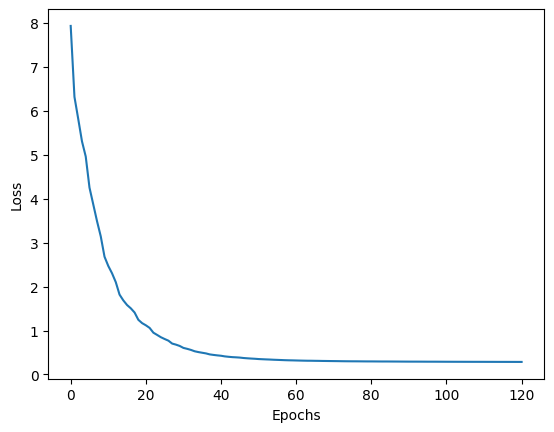

[ 7.45001833e-01  1.00238402e-01 -2.60455507e-01  2.94991599e-01
  1.07077049e-02 -8.42431517e-02 -7.79654826e-01 -7.48701809e-01
 -3.10862447e-16]


In [19]:
history = Gradient_decent(X_tr, y_tr, learning_rate=0.05, batch_size=500, epochs=30, seed=42)

A = np.c_[X_tr, np.ones(len(X_tr))]
print(np.linalg.lstsq(A, y_tr_s, rcond=None)[0])   # [w, b]

Epoch 1/30, Loss: 7.5861, w: [ 0.289 -1.076  0.741  0.932 -1.899 -1.304  0.101 -0.286], b: 0.0852
Epoch 1/30, Loss: 6.5903, w: [ 0.39  -1.141  0.809  0.931 -1.461 -1.309 -0.022 -0.157], b: 0.2333
Epoch 1/30, Loss: 6.3618, w: [ 0.402 -1.075  0.801  0.92  -1.476 -1.31  -0.053 -0.14 ], b: 0.3020
Epoch 1/30, Loss: 6.0636, w: [ 0.503 -1.063  0.814  0.903 -1.427 -1.312 -0.093 -0.119], b: 0.4039
Epoch 1/30, Loss: 24.6340, w: [ 1.181 -0.73   0.627  0.769 -0.278  6.534  0.119 -0.339], b: 0.6946
Epoch 1/30, Loss: 24.2980, w: [ 1.154 -0.668  0.594  0.749 -0.265  6.53   0.096 -0.327], b: 0.8060
Epoch 1/30, Loss: 24.0522, w: [ 1.123 -0.645  0.565  0.74  -0.29   6.528  0.074 -0.305], b: 0.8763
Epoch 1/30, Loss: 23.8473, w: [ 1.114 -0.623  0.524  0.725 -0.199  6.525  0.019 -0.27 ], b: 0.9683
Epoch 1/30, Loss: 23.7987, w: [ 1.117 -0.606  0.523  0.719 -0.203  6.524  0.031 -0.289], b: 1.0024
Epoch 1/30, Loss: 23.5871, w: [ 1.097e+00 -5.580e-01  5.100e-01  7.180e-01 -2.310e-01  6.521e+00
  5.000e-03 -2.7

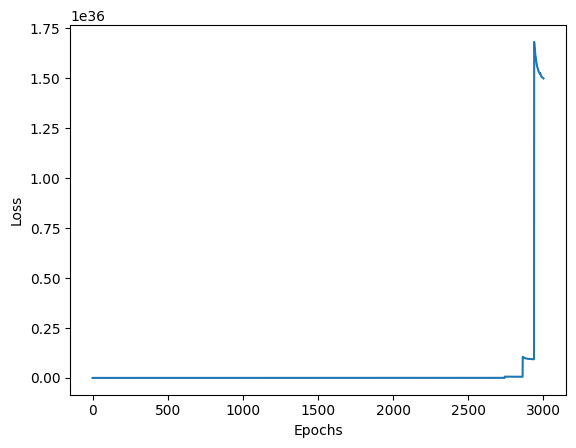

[ 7.45001833e-01  1.00238402e-01 -2.60455507e-01  2.94991599e-01
  1.07077049e-02 -8.42431517e-02 -7.79654826e-01 -7.48701809e-01
 -3.10862447e-16]


In [21]:
history = Gradient_decent(X_tr, y_tr, learning_rate=0.05, batch_size=16, epochs=30, seed=42)

A = np.c_[X_tr, np.ones(len(X_tr))]
print(np.linalg.lstsq(A, y_tr_s, rcond=None)[0])   # [w, b]